In [1]:
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.layers import (Input, Dense, Embedding, Flatten, Concatenate, GRU, Lambda)
from tensorflow.keras.models import Model
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import matplotlib.pyplot as plt

In [2]:
from google.colab import drive
drive.mount('/content/drive',force_remount=True)

Mounted at /content/drive


In [3]:
symbols = ["AAPL","AIG","BAC","GS","MNST","MSFT","NKE","PFE","PLUG","SHOP","SPCE"]
path = "/content/drive/MyDrive/Βαση Δεδομενων/"

datasets = []

for symbol in symbols:
    df = pd.read_excel(
        f"{path}{symbol}_Data_Technical_Indicators_Combined.xlsx",
        parse_dates=[0]
    )
    df.rename(columns={df.columns[0]: "Date"}, inplace=True)
    df.set_index("Date", inplace=True)
    df = df.sort_index()
    # Δημιουργία Volatility
    df["Volatility"] = df.iloc[:, 8].shift(-1)
    df["Symbol"] = symbol
    datasets.append(df)

# Κοινές ημερομηνίες για όλες τις μετοχές
common_dates = datasets[0].index
for df in datasets[1:]:
    common_dates = common_dates.intersection(df.index)

# Φιλτράρουμε όλα τα dataframes για τις κοινές ημερομηνίες
for i in range(len(datasets)):
    datasets[i] = datasets[i].loc[common_dates]

# Ενοποίηση όλων των datasets
dataset = pd.concat(datasets, axis=0)
dataset = dataset.dropna()

le = LabelEncoder()
dataset["Symbol_enc"] = le.fit_transform(dataset["Symbol"])
num_symbols = dataset["Symbol_enc"].nunique()

# Features και target
X_volatility_num = dataset.iloc[:, [1, 2, 3, 9, 10, 11, 5, 16]]
X_volatility_sym = dataset["Symbol_enc"]
y_volatility = np.log1p(dataset["Volatility"])

In [4]:
print(X_volatility_num)
print(X_volatility_sym)
print(y_volatility)

                 High        Low      Close  Real Upper Band  \
Date                                                           
2019-01-02  37.930661  36.827482  37.708591          43.4714   
2019-01-03  34.795449  33.907176  33.952545          42.8920   
2019-01-04  35.471204  34.336985  35.401955          42.4470   
2019-01-07  35.538069  34.838433  35.323162          42.0077   
2019-01-08  36.252032  35.464047  35.996532          41.7450   
...               ...        ...        ...              ...   
2024-12-23   6.220000   6.015000   6.120000           7.3798   
2024-12-24   6.220000   5.940000   6.210000           7.2129   
2024-12-26   6.670000   6.070000   6.500000           7.1512   
2024-12-27   6.770000   6.360000   6.380000           7.0739   
2024-12-30   6.240000   5.820000   5.980000           6.9129   

            Real Middle Band  Real Lower Band      RSI        VIX  
Date                                                               
2019-01-02           39.1471   

In [5]:
# GRU parameters
TIMESTEPS = 10

def create_sequences(X_volatility_num, X_volatility_sym, y_volatility, timesteps):
    Xn, Xs, yt = [], [], []

    for sym in np.unique(X_volatility_sym):
        mask = (X_volatility_sym == sym)

        X_volatility_sym_df = X_volatility_num.loc[mask].reset_index(drop=True)
        y_volatility_sym = y_volatility.loc[mask].reset_index(drop=True)

        for i in range(timesteps, len(X_volatility_sym_df)):
            Xn.append(X_volatility_sym_df.iloc[i-timesteps:i].values)
            Xs.append(sym)
            yt.append(y_volatility_sym.iloc[i])

    return np.array(Xn), np.array(Xs), np.array(yt)

In [6]:
test_size = 0.2
total_len = len(common_dates)
test_len = int(total_len * test_size)

train_dates = common_dates[:-test_len]
test_dates  = common_dates[-test_len:]

X_num_train = X_volatility_num.loc[X_volatility_num.index.isin(train_dates)]
X_sym_train = X_volatility_sym.loc[X_volatility_sym.index.isin(train_dates)]
y_train = y_volatility.loc[y_volatility.index.isin(train_dates)]

X_num_test = X_volatility_num.loc[X_volatility_num.index.isin(test_dates)]
X_sym_test = X_volatility_sym.loc[X_volatility_sym.index.isin(test_dates)]
y_test = y_volatility.loc[y_volatility.index.isin(test_dates)]

train_dates_sorted = X_num_train.index.unique().sort_values()
val_len = int(len(train_dates_sorted) * 0.2)

train_dates_final = train_dates_sorted[:-val_len]
val_dates = train_dates_sorted[-val_len:]

X_num_train_final = X_volatility_num.loc[X_volatility_num.index.isin(train_dates_final)]
X_sym_train_final = X_volatility_sym.loc[X_volatility_sym.index.isin(train_dates_final)]
y_train_final = y_volatility.loc[y_volatility.index.isin(train_dates_final)]

X_num_val = X_volatility_num.loc[X_volatility_num.index.isin(val_dates)]
X_sym_val = X_volatility_sym.loc[X_volatility_sym.index.isin(val_dates)]
y_val = y_volatility.loc[y_volatility.index.isin(val_dates)]

In [7]:
# Feature scaling
sc = StandardScaler()
X_num_train_final = sc.fit_transform(X_num_train_final)
X_num_val = sc.transform(X_num_val)
X_num_test = sc.transform(X_num_test)

In [8]:
# Sequences
Xn_train, Xs_train, y_train_seq = create_sequences( pd.DataFrame(X_num_train_final), X_sym_train_final.reset_index(drop=True), y_train_final.reset_index(drop=True), TIMESTEPS )
Xn_val, Xs_val, y_val_seq = create_sequences( pd.DataFrame(X_num_val), X_sym_val.reset_index(drop=True), y_val.reset_index(drop=True), TIMESTEPS )
Xn_test, Xs_test, y_test_seq = create_sequences( pd.DataFrame(X_num_test), X_sym_test.reset_index(drop=True), y_test.reset_index(drop=True), TIMESTEPS )

In [9]:
# Νευρωνικό Δίκτυο
num_input = Input(shape=(TIMESTEPS, Xn_train.shape[2]), name="num_input")
sym_input = Input(shape=(1,), name="sym_input")

sym_embed = Embedding(num_symbols, 4)(sym_input)
sym_embed = Flatten()(sym_embed)

time_positions = Lambda(lambda z: tf.tile(tf.reshape(tf.linspace(0.0, 1.0, tf.shape(z)[1]), (1, -1, 1)), [tf.shape(z)[0], 1, 1]))(num_input)

sequence_with_time = Concatenate(axis=-1)([num_input, time_positions])

x = GRU(64)(sequence_with_time)
x = Concatenate()([x, sym_embed])
x = Dense(32, activation="relu")(x)
x = Dense(16, activation="relu")(x)
output = Dense(1, activation="linear")(x)
model = Model([num_input, sym_input], output)
model.compile(optimizer=Adam(0.0005), loss="mean_squared_error", metrics=[tf.keras.metrics.MeanAbsoluteError(name='mae'),tf.keras.metrics.RootMeanSquaredError(name='rmse'),tf.keras.metrics.MeanAbsolutePercentageError(name='mape')])
early_stopping = EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True )
history=model.fit([Xn_train, Xs_train],y_train_seq, validation_data=([Xn_val, Xs_val], y_val_seq), epochs=1000, batch_size=16, callbacks=[early_stopping])

Epoch 1/1000
658/658 ━━━━━━━━━━━━━━━━━━━━ 10s 11ms/step - loss: 0.2328 - mae: 0.2842 - mape: 30.7369 - rmse: 0.4825 - val_loss: 0.0449 - val_mae: 0.1450 - val_mape: 12.3751 - val_rmse: 0.2119
Epoch 2/1000
658/658 ━━━━━━━━━━━━━━━━━━━━ 7s 11ms/step - loss: 0.0277 - mae: 0.1178 - mape: 15.1698 - rmse: 0.1664 - val_loss: 0.0394 - val_mae: 0.1409 - val_mape: 11.3339 - val_rmse: 0.1984
Epoch 3/1000
658/658 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - loss: 0.0198 - mae: 0.1004 - mape: 11.3538 - rmse: 0.1407 - val_loss: 0.0299 - val_mae: 0.1264 - val_mape: 10.9114 - val_rmse: 0.1729
Epoch 4/1000
658/658 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - loss: 0.0171 - mae: 0.0942 - mape: 10.7017 - rmse: 0.1306 - val_loss: 0.0188 - val_mae: 0.1006 - val_mape: 9.3608 - val_rmse: 0.1373
Epoch 5/1000
658/658 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - loss: 0.0120 - mae: 0.0825 - mape: 9.3709 - rmse: 0.1098 - val_loss: 0.0149 - val_mae: 0.0904 - val_mape: 8.4008 - val_rmse: 0.1223
Epoch 6/1000
658/658 ━━━━━━━━━━━━━━━━━━━━ 7s 11ms

In [10]:
test_loss, test_mae , test_rmse, test_mape = model.evaluate([Xn_test,Xs_test], y_test_seq)
print(f"Test Loss (MSE): {test_loss}, Test MAE: {test_mae}")

101/101 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0163 - mae: 0.0974 - mape: 11.3581 - rmse: 0.1276
Test Loss (MSE): 0.01629301719367504, Test MAE: 0.09736091643571854


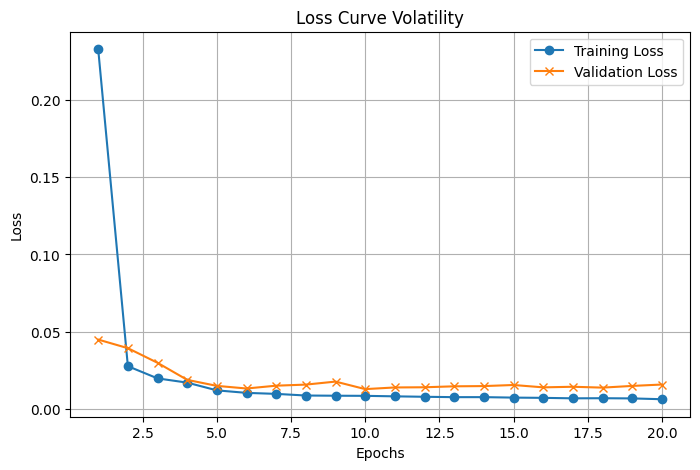

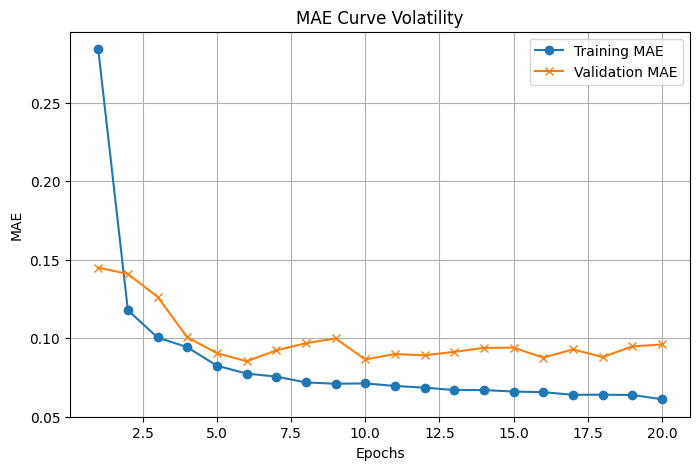

In [11]:
# Γραφικές παραστάσεις
epochs = range(1, len(history.history['loss']) + 1)

# Loss Curve
plt.figure(figsize=(8, 5))
plt.plot(epochs, history.history['loss'], label='Training Loss', marker='o')
plt.plot(epochs, history.history['val_loss'], label='Validation Loss', marker='x')
plt.title('Loss Curve Volatility')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()

# MAE Curve
plt.figure(figsize=(8, 5))
plt.plot(epochs, history.history['mae'], label='Training MAE', marker='o')
plt.plot(epochs, history.history['val_mae'], label='Validation MAE', marker='x')
plt.title('MAE Curve Volatility')
plt.xlabel('Epochs')
plt.ylabel('MAE')
plt.legend()
plt.grid(True)
plt.show()

In [12]:
y_pred = model.predict([Xn_test,Xs_test])

y_test_real = np.expm1(y_test_seq).reshape(-1)
y_pred_real = np.expm1(y_pred).reshape(-1)


mae  = mean_absolute_error((y_test_real), (y_pred_real))
rmse = np.sqrt(mean_squared_error((y_test_real), (y_pred_real)))
mape = np.mean(np.abs(((y_test_real) - (y_pred_real)) / (y_test_real))) * 100
r2   = r2_score((y_test_real), (y_pred_real))
relative_mae = mae / np.mean(y_test_real) * 100

print(f"MAE  : {mae:.2f}")
print(f"RMSE : {rmse:.2f}")
print(f"MAPE : {mape:.2f}%")
print(f"R²   : {r2:.3f}")
print(f"Relative MAE: {relative_mae:.2f}%")

101/101 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step
MAE  : 0.43
RMSE : 0.77
MAPE : 16.98%
R²   : 0.930
Relative MAE: 15.45%
